# **Pathly**
## **M3 Design (Updated)**
**Team Members**: Sammi Chong, Ellie Lu, Naseeha Masub, Saba Sohail @ Stony Brook University

---
### **Overview**
Pathly is a mobile public transportation app built with React Native and Expo for riders in the New York City and Long Island area. Since M2, the design has moved from a plan to a working system: riders can see nearby transit with live arrivals, search for a place or stop, compare real transit itineraries, and follow an active trip step by step.

The app talks to a Firebase backend. **Cloud Functions** do all of the transit work: reading each agency's GTFS schedule, merging GTFS-Realtime feeds, planning trips through the Google Routes API, estimating fares, and computing walking paths. **Cloud Firestore** stores rider data (profile, recent searches, previous destinations, and saved places). **Cloud Storage** holds versioned GTFS snapshots that a scheduled function refreshes every day.

This document updates the M2 design to match what we built, and calls out where the design changed and why.

---
### **What Changed Since M2**

| Area | M2 plan | M3 design | Why |
|---|---|---|---|
| **Authentication** | Google OAuth, with a guest option | Email and password through Firebase Authentication | Simpler to set up across web, iOS and Android in Expo. Google sign-in is still a possible follow-up. |
| **Transit data** | Read GTFS / GTFS-RT feeds | A backend pipeline: a daily refresh job, versioned snapshots in Cloud Storage, and prebuilt per-route indexes | Reading the full `stop_times.txt` on every cold start made the first nearby search take about 18 seconds |
| **Agencies** | MTA Bus, Subway, NYC Ferry, LIRR, NICE, Suffolk | All of these, plus the Staten Island Ferry; MTA Bus is split into its six feeds (Bronx, Brooklyn, Manhattan, Queens, Staten Island, MTA Bus Co.) | Each MTA bus feed is published separately |
| **Trip planning** | Mapping + routing API | `planTrip` Cloud Function calls the Google Routes API, then Pathly adds live data and its own fare estimates | Keeps the API key on the server and lets us price LIRR, NICE and Suffolk trips, which Google doesn't |
| **API keys** | Not specified | Backend keys live in Firebase Secret Manager; App Check is being rolled out | Billable keys should never ship inside the app |
| **Route navigation** | Mapping + routing API | An en-route mode that follows the rider's location, survives an app restart, and saves finished trips to Recents | Turned trip results into a complete experience for the demo |
| **Themes** | One light palette | Light, dark, and high-contrast palettes, plus standard colors per agency and line | Accessibility, and riders recognize official line colors |
| **Testing** | Postman and manual device testing | About 500 automated tests, run on every pull request by GitHub Actions | The app grew too large to check by hand |

---
### **Architecture**

The architecture is the client-server design from M2, now filled in. The mobile app never calls Google or transit feeds directly with a secret key; it calls Firebase callable functions, which do that work and return small, ready-to-display results.

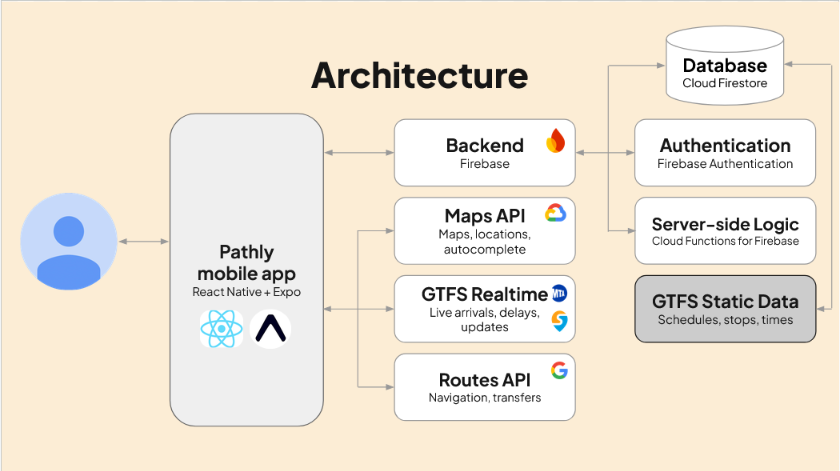

**How a request flows (example: Nearby):**
1. The app reads the rider's location with `expo-location`.
2. It calls the `findNearbyTransit` callable function, signed in through Firebase Authentication.
3. The function looks up nearby stops in the current GTFS snapshot's prebuilt index, then the app asks `getRoutesLiveStatus` for live arrivals for the routes it shows.
4. The function fetches and merges each agency's GTFS-Realtime feed, matches live trips to the schedule, and adds service alerts.
5. The app refreshes live data every 15 seconds while the screen is open, and again when the rider moves.

**Cloud Functions:**

| Function | Purpose |
|---|---|
| `findNearbyTransit` | Stops and routes near the rider |
| `getRouteLiveStatus` / `getRoutesLiveStatus` | Live arrivals, vehicle positions, delays and alerts for one or many routes |
| `getStopDepartures` | Upcoming departures at a stop, live where available, otherwise scheduled |
| `getNearestRouteStop` | The closest stop on a chosen route |
| `getRouteGeometry` | The shape of a route for drawing on the map |
| `getWalkingPath` | A walking path to a stop, from prebuilt walking tiles |
| `planTrip` | Transit itineraries from the Google Routes API, plus fares and live data |
| `searchTransitStops` | Stop search by name |
| `geocodeAddress` | Turns an address into coordinates |
| `getBackendStatus` | Health check used by the admin tools |
| `refreshGtfsStaticData` | Scheduled daily at 04:00 New York time to refresh every agency's GTFS feed |

---
### **Stack**

The stack chosen in M2 held up. We stayed with Firebase because authentication, database, storage, scheduled jobs and server code all live in one place, which let us spend our time on transit features instead of infrastructure.

| Layer | Technology |
|---|---|
| **frontend** | React Native 0.86 + Expo 57, TypeScript |
| **maps** | `react-native-maps` on iOS/Android, `@react-google-maps/api` on web |
| **place search** | Google Places Autocomplete (Places API (New)) |
| **backend** | Firebase (Blaze plan) |
| **server-side logic** | Cloud Functions for Firebase (Node 24, TypeScript) |
| **database** | Cloud Firestore |
| **file storage** | Firebase Cloud Storage (GTFS snapshots) |
| **authentication** | Firebase Authentication (email and password) |
| **secrets / abuse protection** | Firebase Secret Manager, App Check, per-user rate limits |
| **trip planning** | Google Routes API |
| **CI** | GitHub Actions |

The repository is an npm workspace with two packages: `mobile/` (the Expo app) and `firebase/functions/` (the backend).

---
### **Design Goals**

- **Accuracy** - Live GTFS-Realtime data is merged with each agency's schedule, so riders see real arrivals instead of timetable guesses. Where an agency has no live feed (the Staten Island Ferry), departures come from the schedule and the app says so. Fares for LIRR, NICE and Suffolk trips are estimated from the agencies' published 2026 fares and labeled as estimates ("~$18.25").
- **Simplicity** - The home screen opens straight to the map and nearby transit. Saved places sit in a strip on the home screen and as pins on the map, so common trips take one or two taps.
- **Scalability** - Every agency is described by one config entry in `gtfsAgencies.ts` (where its feeds live, how its live trips match the schedule, which secret it needs). Adding the Staten Island Ferry and the six MTA bus feeds only required new entries, not changes to the trip logic.
- **Speed** *(new)* - Prebuilt indexes, cached snapshots, batched live-status requests and a device cache keep cold starts and repeat views fast.

---
### **Design Specifications**

Status of the core features from M2:

| Feature | Implementation | Status |
|---|---|---|
| display nearby transit | device location + `findNearbyTransit` + walking-distance sorting | Done |
| display transit routes | route detail view with stops, map shape, transfers and live vehicles | Done |
| search for destination | Google Places Autocomplete + transit stop search | Done |
| compare routes | route results based on time, transfers and fare | Done |
| route navigation | en-route mode driven by location, resumable after restart | Done (rerouting and background navigation are future work) |
| view scheduled transit | GTFS static data, refreshed daily | Done |
| view real-time transit | GTFS-RT through MTA, MTA Bus Time, Swiftly and NYC Ferry feeds | Done |
| view service alerts | GTFS-RT service alerts shown as route notices | Done |
| login | Firebase Authentication (email and password) | Done |
| user profiles | Cloud Firestore; includes account deletion | Done |
| save favorite routes/stops/locations | saved places in Firestore, shown as home map pins | Done (saved places; saved routes not yet) |
| settings | appearance, accessibility (high contrast), preferences | Done |
| admin / debug tools | mock time and location, request log, backend status | Done |
| friends | Firebase | Not started |
| widgets | native iOS/Android + backend | Not started |
| notifications | Expo + Firebase Cloud Functions | Not started |

---
### **Frontend Design**

We kept dark blue as the primary color and Nunito as the font (Regular, SemiBold, Bold and ExtraBold weights). The M2 palette became the light theme, and we added dark and high-contrast versions.

| Role | Light | Dark | Purpose |
|---|---|---|---|
| **primary** | #0B4F9C | #5B9BF8 | main buttons, active states, logo |
| **accent** | #A7D8FF | #2F5E93 | secondary buttons, highlights, selected elements |
| **background** | #F7FAFF | #000000 | main app background |
| **success** | #16A34A | #34C06B | confirmations, live transit |
| **warning** | #F97316 | #FB923C | delays, alerts, warnings |

High-contrast mode (Settings → Accessibility) darkens text and borders and deepens the primary color, for example primary #063A75 in light mode.

**Route colors:** each line uses its agency's official color (for example, subway lines use MTA bullet colors), and lines without an official color get one standard color per agency instead of a random one. The same rule runs on the backend and in the app so badges and map lines always match.

**Main screens:**
- **Home** - the map with nearby transit in a single scrolling sheet, saved places, recent trips, and a card to resume an active trip
- **Search** - places and transit stops, with recent searches
- **Route Results** - itineraries to compare, with a leave-time picker
- **Planned Trip Detail** - each leg of the trip on a map
- **En-route Navigation** - the current instruction, next stop, stops remaining and arrival estimate
- **Route Detail / Departures** - a line's stops, live vehicles, transfers and alerts
- **Profile and Settings** - account, appearance, accessibility, and admin tools for admin accounts

The map has separate native and web versions (`*.native.tsx` / `*.web.tsx`) because the two platforms need different map libraries.

---
### **Backend/APIs**

| Source | Used for |
|---|---|
| Google Maps (native SDKs and JavaScript API) | the map |
| Google Places API (New) | destination autocomplete |
| Google Routes API | transit itineraries (`planTrip`) |
| Google Geocoding | `geocodeAddress` |
| MTA GTFS and GTFS-RT | subway, LIRR, service alerts |
| MTA Bus Time | live MTA bus data (requires an API key) |
| Swiftly | live NICE and Suffolk County Transit data (requires an API key) |
| NYC Ferry | schedule and live trip updates |
| Staten Island Ferry | schedule only (no live feed) |

**Transit data pipeline.** Every day at 04:00 New York time, `refreshGtfsStaticData` downloads each agency's GTFS feed, validates it, and uploads it to Cloud Storage as a new version under `gtfs/v1/<agency>/`. Only after a feed passes validation does the job update that agency's `current.json` to point to it, so a broken or expired feed never replaces a good one. The same job builds small per-route index files for each version. Functions check for a new version at most every five minutes, keep the last good copy on that server instance, and fall back to the GTFS files bundled with the deployment if Storage is unavailable. Old versions are cleaned up once two newer ones exist.

**Trip planning.** `planTrip` sends the origin, destination and time to the Google Routes API in transit mode, then adds Pathly's own fare estimates, stop lists and live data. Results are cached for 2 minutes and each rider can plan up to 20 trips per minute, which keeps us inside the free tier.

---
### **Database**

The Firestore data model matches our M2 class diagram, with one change: passwords are handled entirely by Firebase Authentication, so Pathly never stores a password hash.

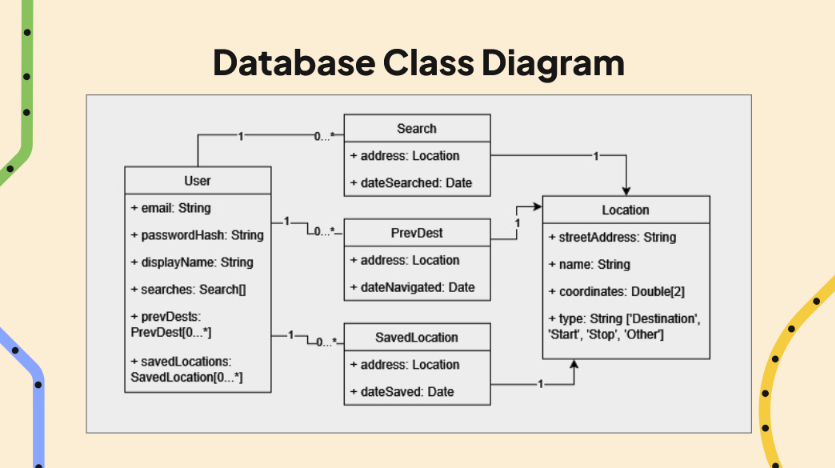

| Path | Contents |
|---|---|
| `users/{uid}` | profile: email, display name |
| `users/{uid}/searches/{placeKey}` | a recent search: place and date searched |
| `users/{uid}/prevDests/{placeKey}` | a previous destination: place and date navigated |
| `users/{uid}/savedLocations/{key}` | a saved place: place and date saved |
| `_pathlyCallableRateLimits` | per-user rate-limit counters (backend only, expire after 24 hours) |

Transit data is **not** stored in Firestore. Schedules live as versioned GTFS files in Cloud Storage, and live data is fetched from the agencies on demand. The active trip and trip history are stored on the device, so a trip can resume after the app restarts.

---
### **User Authentication and Security**

Riders sign up and sign in with email and password through Firebase Authentication. Deleting an account removes the rider's Firestore documents, their data on the device, and their Auth account.

- Every Cloud Function requires a signed-in user.
- Backend keys (Google Maps server key, Swiftly, MTA Bus Time) are stored in Firebase Secret Manager and never shipped in the app. Keys that must be in the app (Maps client and Places) are restricted by platform and API.
- Each rider has request limits, enforced with a Firestore transaction so that extra server instances can't multiply them.
- App Check is ready on the backend. It is enforced for `geocodeAddress` now, and will be turned on for the transit functions once the web and native builds send valid App Check tokens.
- Admin tools are only available to configured admin emails.

---
### **Testing and CI**

| Suite | Runner | Tests | Covers |
|---|---|---|---|
| Backend (`firebase/functions/test/`) | Node test runner | ~158 in 19 files | GTFS parsing per agency using recorded feeds, trip planning, fares, walking paths, stop search, security of callable functions |
| Mobile (`mobile/__tests__/`) | Jest + React Native Testing Library | ~338 in 36 files | screens and components, hooks (active trip, location), navigation logic, data services |

**CI:** a GitHub Actions workflow runs on every pull request and push to `main` and `services`. It installs dependencies, lints, runs both test suites, type-checks, and builds the app.

**Testing challenges:**
- **Live data changes constantly.** We record real feeds as fixtures so tests can replay delays, alerts and missing trips the same way every time.
- **Every agency's feed is different.** Each agency has its own test suite so that fixing one doesn't break another.
- **Location is hard to simulate.** The admin tools can fake the time and the rider's location, and step through a trip's checkpoints, so we can demo en-route navigation without riding the train.
- **Multiple platforms.** Map code differs between native and web, so visual issues still need manual checks on devices and emulators.

**Not covered yet:** end-to-end tests on a real device, tests against the Firebase emulators, and native iOS/Android builds in CI.

---
### **Development Workflow**

We continued using Claude and Codex with **OpenSpec**: before building a feature, we write a change proposal, design and task list, and archive it once it's done. More than 20 changes have been completed this way, including Google Maps search, real trip planning, MTA bus and ferry support, precomputed GTFS indexes and admin debug tools. En-route navigation is the current change.

Each member's development cycle:

- create feature branch
- write or update the OpenSpec change
- develop locally (web, Android emulator, iOS simulator or Expo Go)
- run lint, tests and type-check locally
- pull request
- CI checks pass
- code review (by at least one other member)
- merge into main

Deploying the backend is manual (`npm run deploy:backend`). Before each deploy, Firebase rebuilds the GTFS indexes and stops if they or the walking tiles are out of date.

For this milestone, we divided responsibilities as follows:

| Team Member | Responsibility |
|---|---|
| **Sammi Chong** | *route view and navigation* |
| **Ellie Lu** | *security* |
| **Naseeha Masub** | *-* |
| **Saba Sohail** | *maps* |

---
### **Next Steps**
- Rerouting, off-route detection and background navigation
- Notifications for delays and when to leave
- Saved routes, friends and widgets
- Turn on App Check enforcement for the transit functions
- Run the deploy checks and backend lint in CI; add end-to-end tests
- Release preparation from M2: email service, landing page, analytics, feedback board, app store listings